<a href="https://colab.research.google.com/github/Subhadip24/AIml-Project/blob/main/Heart_Disease_KNN_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Heart Disease Prediction using K-Nearest Neighbors (KNN)

**Dataset:** Kaggle `heart.csv` (303 rows, 13 clinical features, binary target)
**Platform:** Google Colab · **Language:** Python (scikit-learn)

| Team member | Enrollment No. |
|:--|:--|
| Subhadip Mondal | 241001001186 |
| Souradipto Majumdar | 241001001177 |
| Dishtya Thakur | 241001001204 |
| Ayush Saha | 241001001154 |

### Problem statement
> Implement the K-means clustering algorithm or KNN using Python, using a real-life example. Dataset: Kaggle (`heart.csv`). Apply in Google Colab. You can change optimizers, activation functions, add augmentation to the data, or use any kind of fine-tuning method to increase the overall accuracy. Check the overfitting and underfitting concepts by analysing the overall algorithm.

**Real-life example:** a screening aid that flags patients likely to have heart disease from routine check-up measurements.

**Why KNN rather than K-means?** Every patient has a known diagnosis (`target`), so this is *supervised classification*. KNN uses those labels; K-means is unsupervised clustering and would ignore them.

### How this notebook covers the brief

| Requirement | Where |
|:--|:--|
| KNN in Python, Google Colab | Whole notebook (`KNeighborsClassifier`) |
| Real-life example, Kaggle `heart.csv` | Sections 1–2 |
| **Change optimizers / activation functions** | **Not applicable to KNN.** KNN has no training loop, so it has no optimizer or activation function. We tune its equivalent hyperparameters instead: **K**, **distance metric**, **vote weighting** and **feature scaler** (Sections 5, 8, 9). |
| Fine-tuning to increase accuracy | Section 5 (K sweep with cross-validation), Section 8 (GridSearchCV), Section 9 (scaler comparison) |
| Data augmentation | Section 7 (SMOTE) |
| Overfitting & underfitting | Section 6 (train vs. validation accuracy, learning curves, bias-variance plot) |
| Honest evaluation | Section 10 (repeated cross-validation) and Section 11 (summary) |

**Leakage-free design:** every model is a `Pipeline` (scaler → [SMOTE] → KNN), so the scaler and SMOTE are fitted only on the training part of each split, including inside every cross-validation fold.

---
## 1. Import Libraries & Load Data

In [1]:
# Install imbalanced-learn for SMOTE (not pre-installed in Colab)
!pip install imbalanced-learn -q

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score,
    learning_curve,
    StratifiedKFold,
    RepeatedStratifiedKFold,
)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    recall_score,
)
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

RANDOM_STATE = 42
# One fixed cross-validation scheme, reused everywhere so results are comparable
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)


def make_knn(scaler=None, **knn_params):
    """Scaler + KNN in one Pipeline, so scaling is learned only from training data."""
    return Pipeline([
        ('scaler', scaler if scaler is not None else StandardScaler()),
        ('knn', KNeighborsClassifier(**knn_params)),
    ])

print('All libraries imported successfully!')

All libraries imported successfully!


In [3]:
# Load heart.csv: use the local copy if present (Colab upload or cloned repo),
# otherwise read it directly from the project's GitHub repository.
DATA_URL = 'https://raw.githubusercontent.com/Subhadip24/AIml-Project/main/heart.csv'

if os.path.exists('heart.csv'):
    df = pd.read_csv('heart.csv')
    print('Loaded local heart.csv')
else:
    df = pd.read_csv(DATA_URL)
    print('Loaded heart.csv from GitHub')

# (Optional) to upload manually in Colab instead:
# from google.colab import files; files.upload()

print('=' * 60)
print('HEART DISEASE PREDICTION USING KNN')
print('=' * 60)
print(f'\nDataset shape : {df.shape}')
print(f'Features      : {list(df.columns[:-1])}')
print("Target column : 'target' (1 = disease, 0 = no disease)")
df.head()

Loaded local heart.csv
HEART DISEASE PREDICTION USING KNN

Dataset shape : (303, 14)
Features      : ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target column : 'target' (1 = disease, 0 = no disease)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
print('Basic Statistics:')
df.describe().T

Basic Statistics:


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [5]:
print(f'Missing values:\n{df.isnull().sum()}')
print(f'\nDuplicate rows: {df.duplicated().sum()}')

# Remove duplicates if any
df = df.drop_duplicates().reset_index(drop=True)
print(f'Shape after removing duplicates: {df.shape}')

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate rows: 1
Shape after removing duplicates: (302, 14)


---
## 2. Exploratory Data Analysis (EDA)

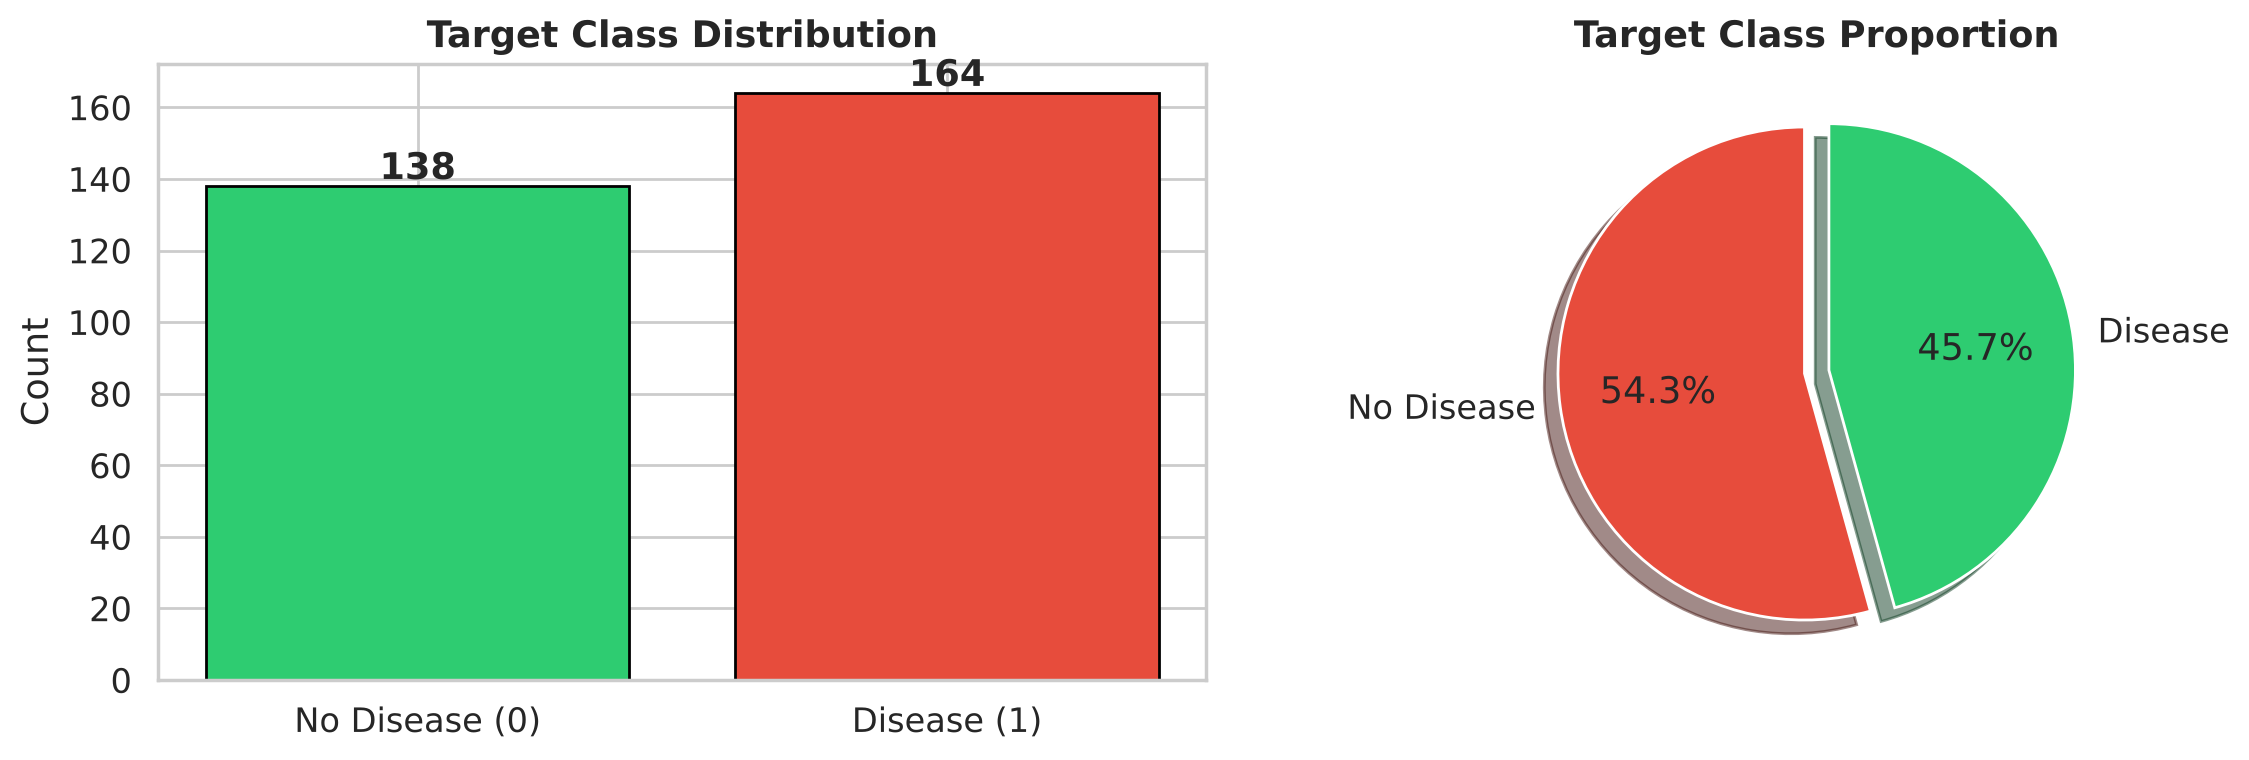

In [6]:
# --- Target Distribution ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_counts = df['target'].value_counts()
colors = ['#e74c3c', '#2ecc71']

axes[0].bar(target_counts.index, target_counts.values, color=colors, edgecolor='black')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['No Disease (0)', 'Disease (1)'])
axes[0].set_title('Target Class Distribution', fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(target_counts.values):
    axes[0].text(target_counts.index[i], v + 2, str(v), ha='center', fontweight='bold')

axes[1].pie(
    target_counts.values,
    labels=['No Disease', 'Disease'],
    colors=colors,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.05, 0.05),
    shadow=True,
)
axes[1].set_title('Target Class Proportion', fontweight='bold')
plt.tight_layout()
plt.show()

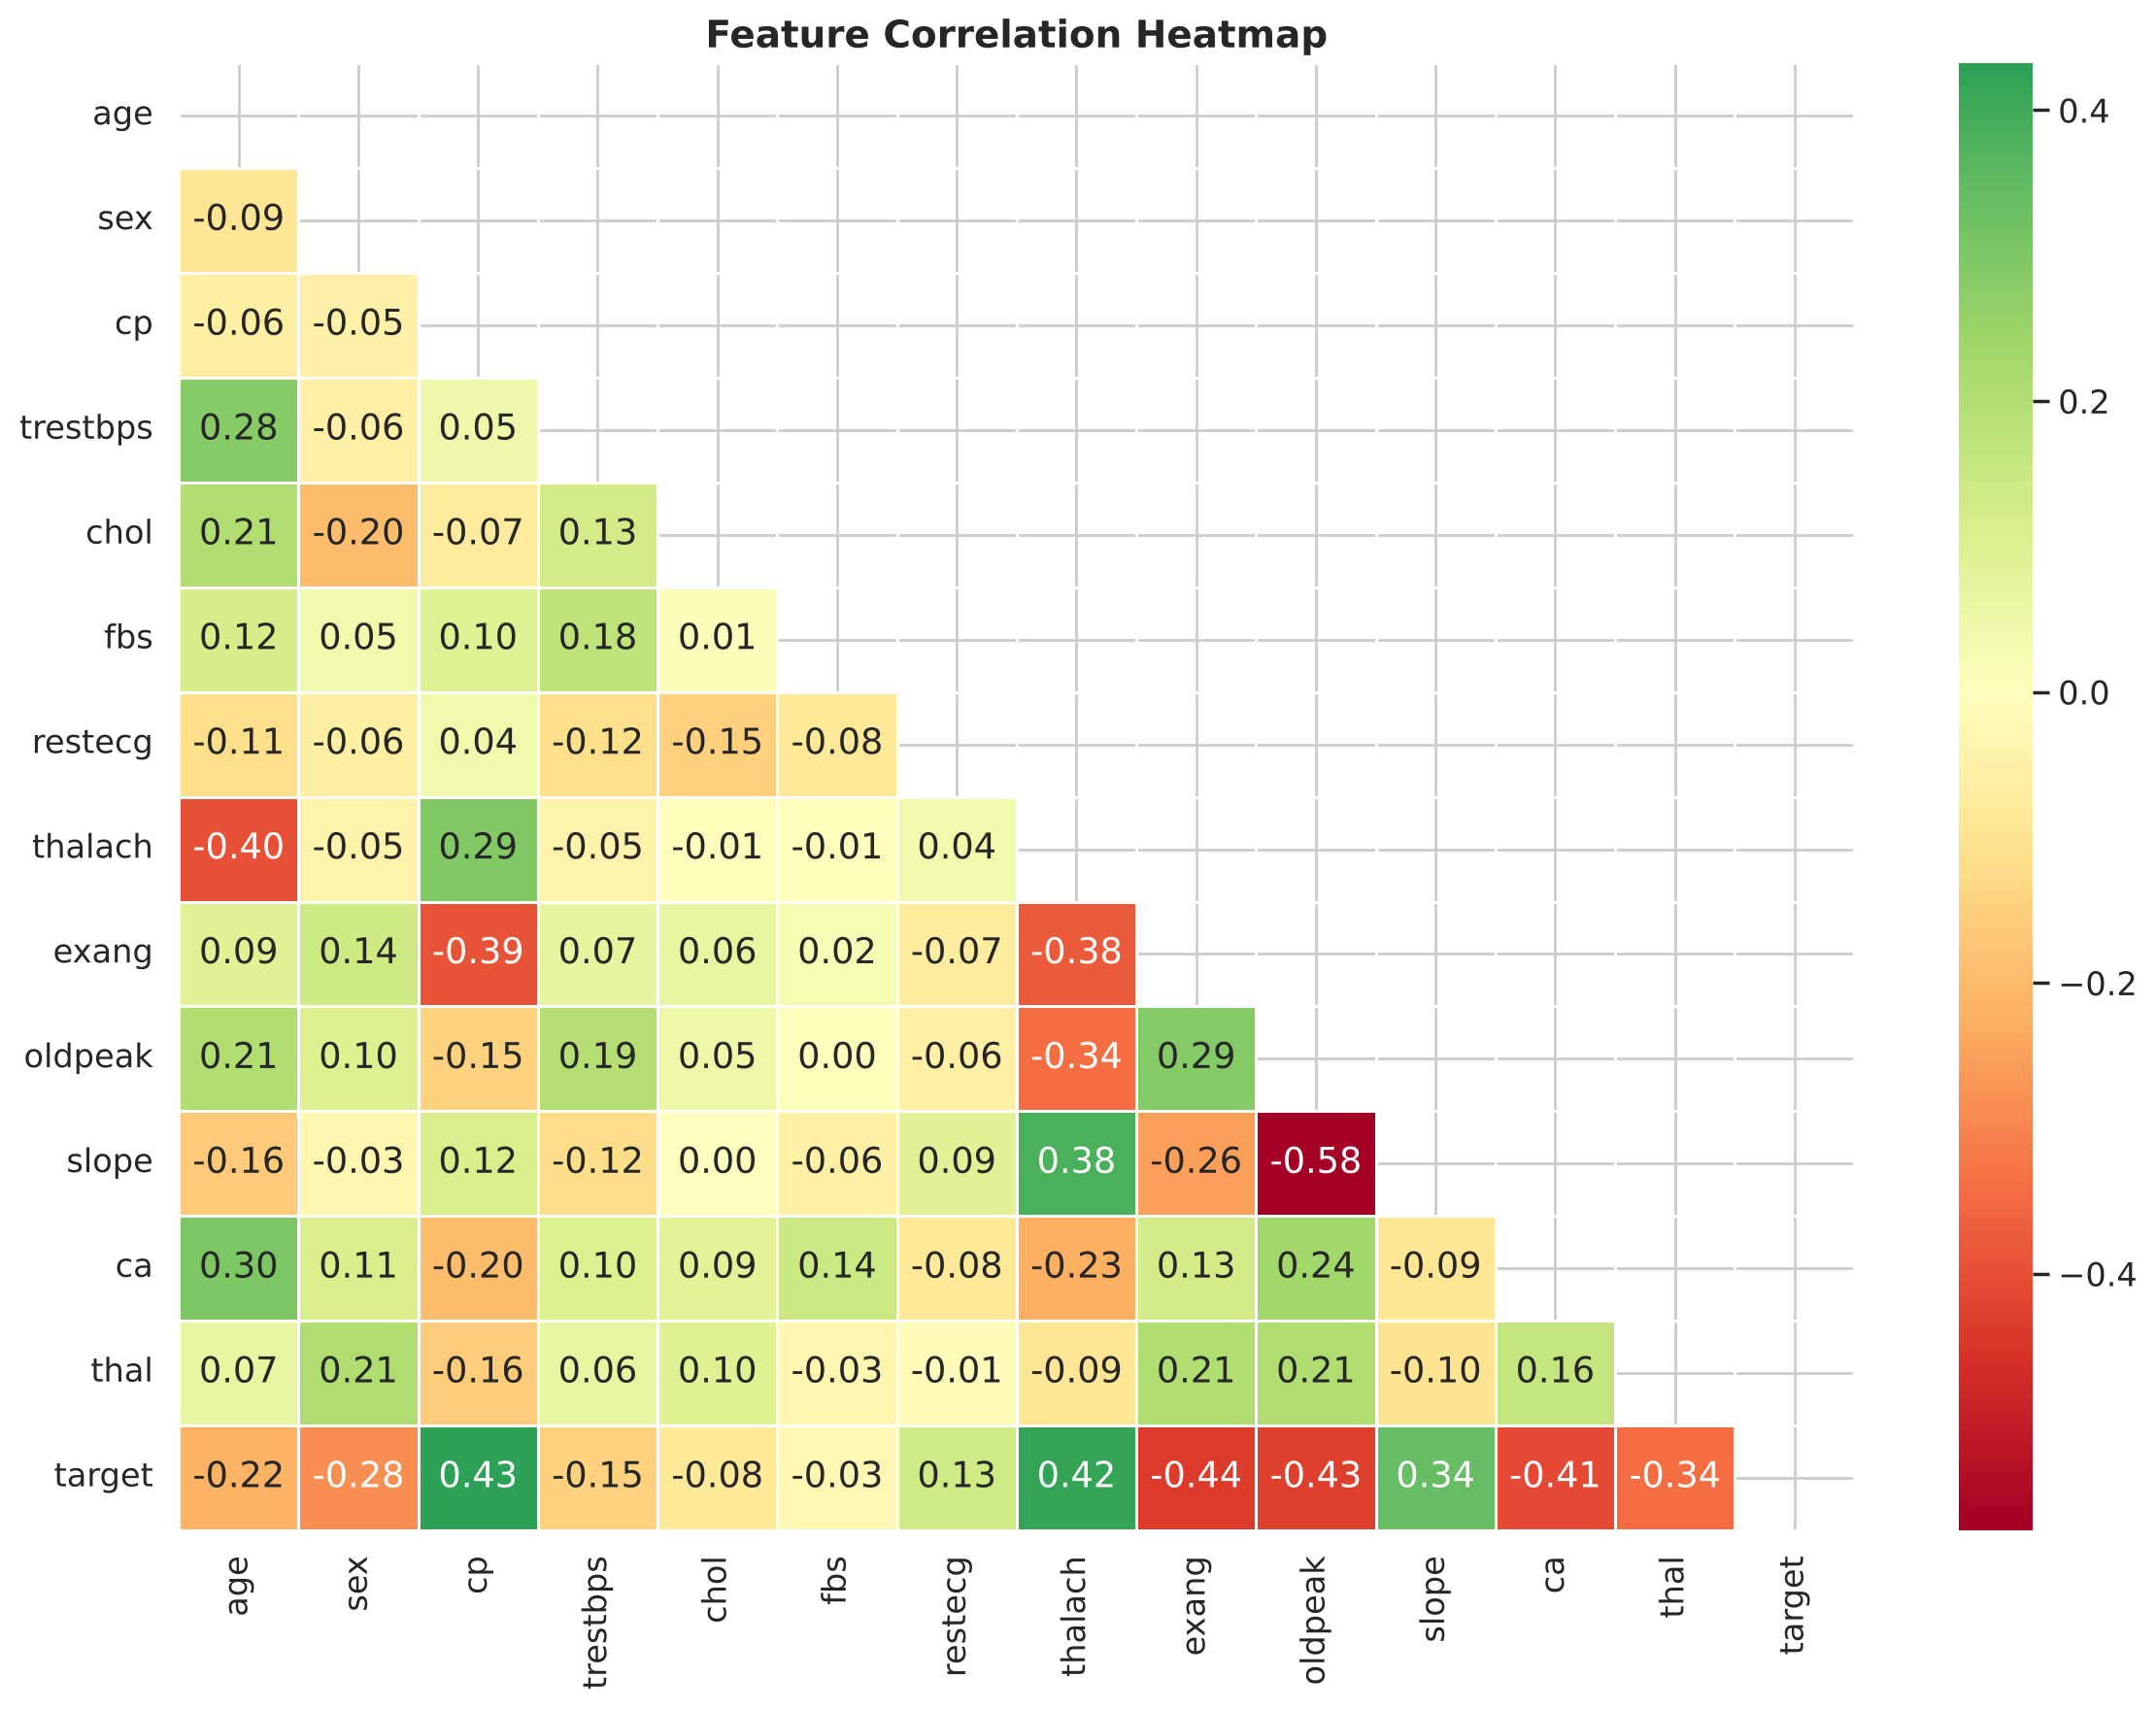

In [7]:
# --- Correlation Heatmap ---
fig, ax = plt.subplots(figsize=(12, 9))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f',
    cmap='RdYlGn', center=0, linewidths=0.5, ax=ax,
)
ax.set_title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

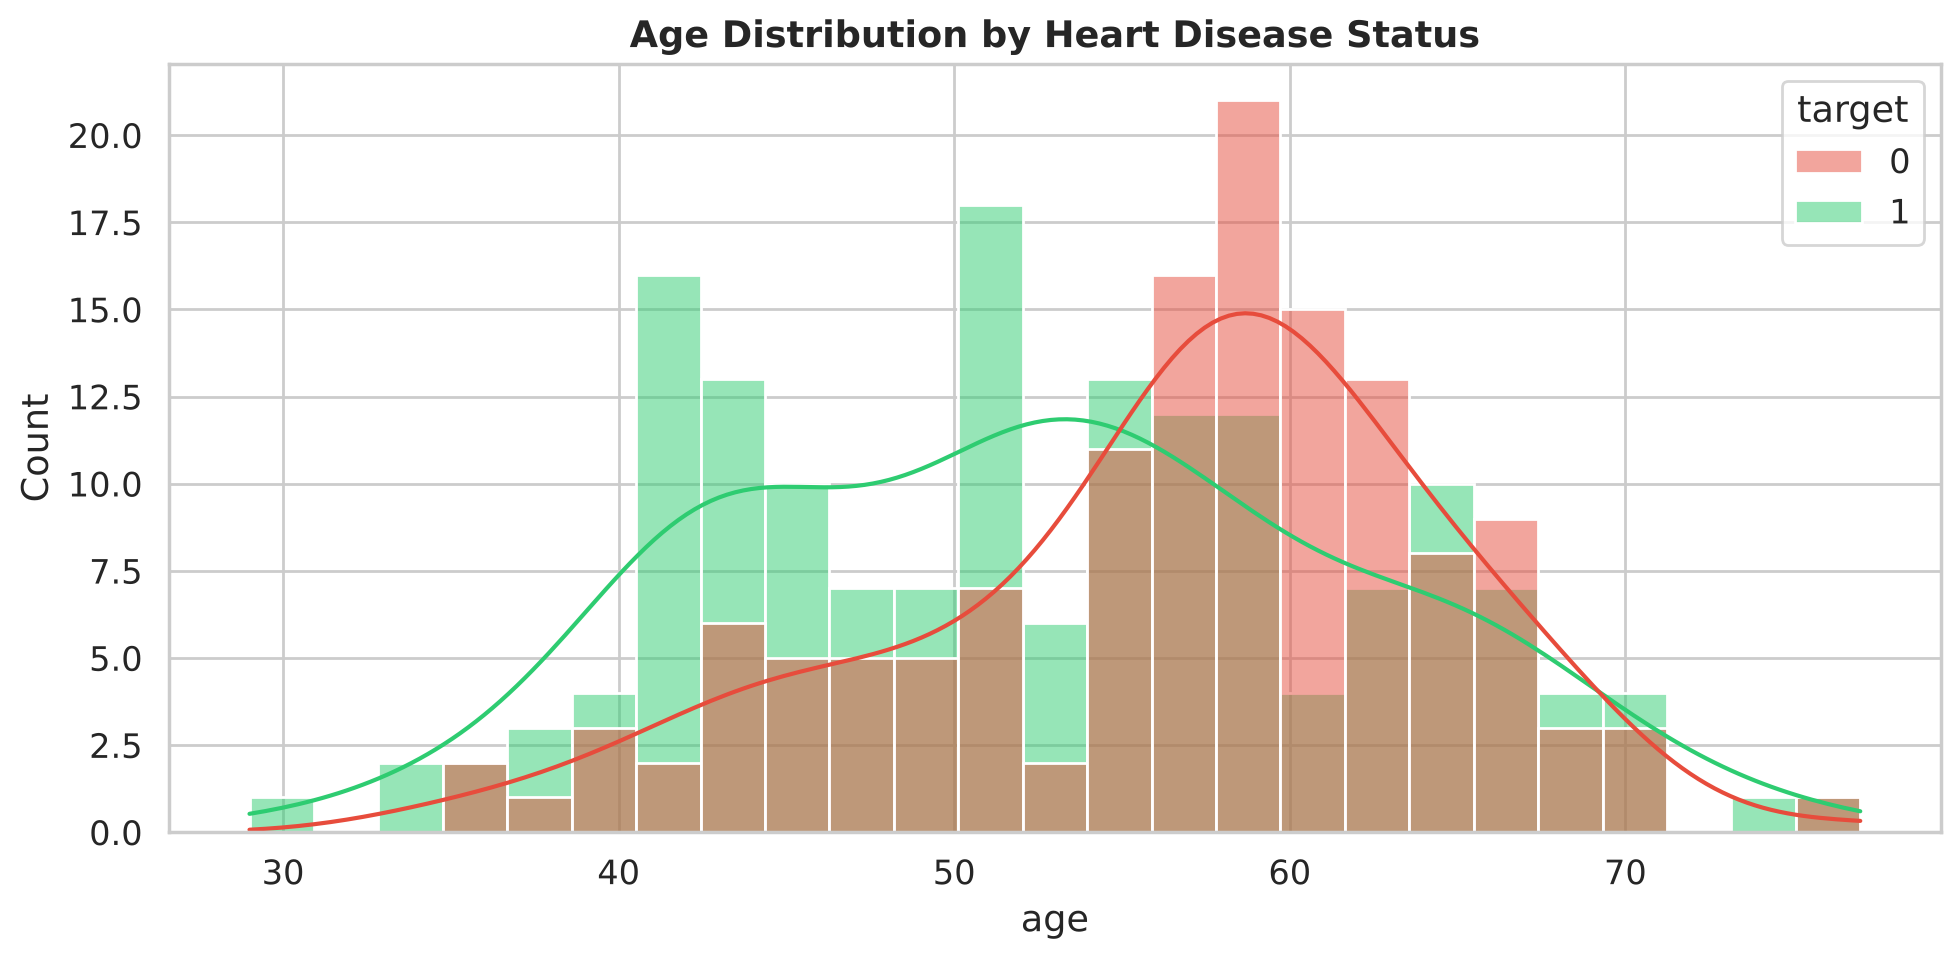

In [8]:
# --- Age Distribution by Target ---
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x='age', hue='target', kde=True, bins=25, palette=colors, ax=ax)
ax.set_title('Age Distribution by Heart Disease Status', fontweight='bold')
plt.tight_layout()
plt.show()

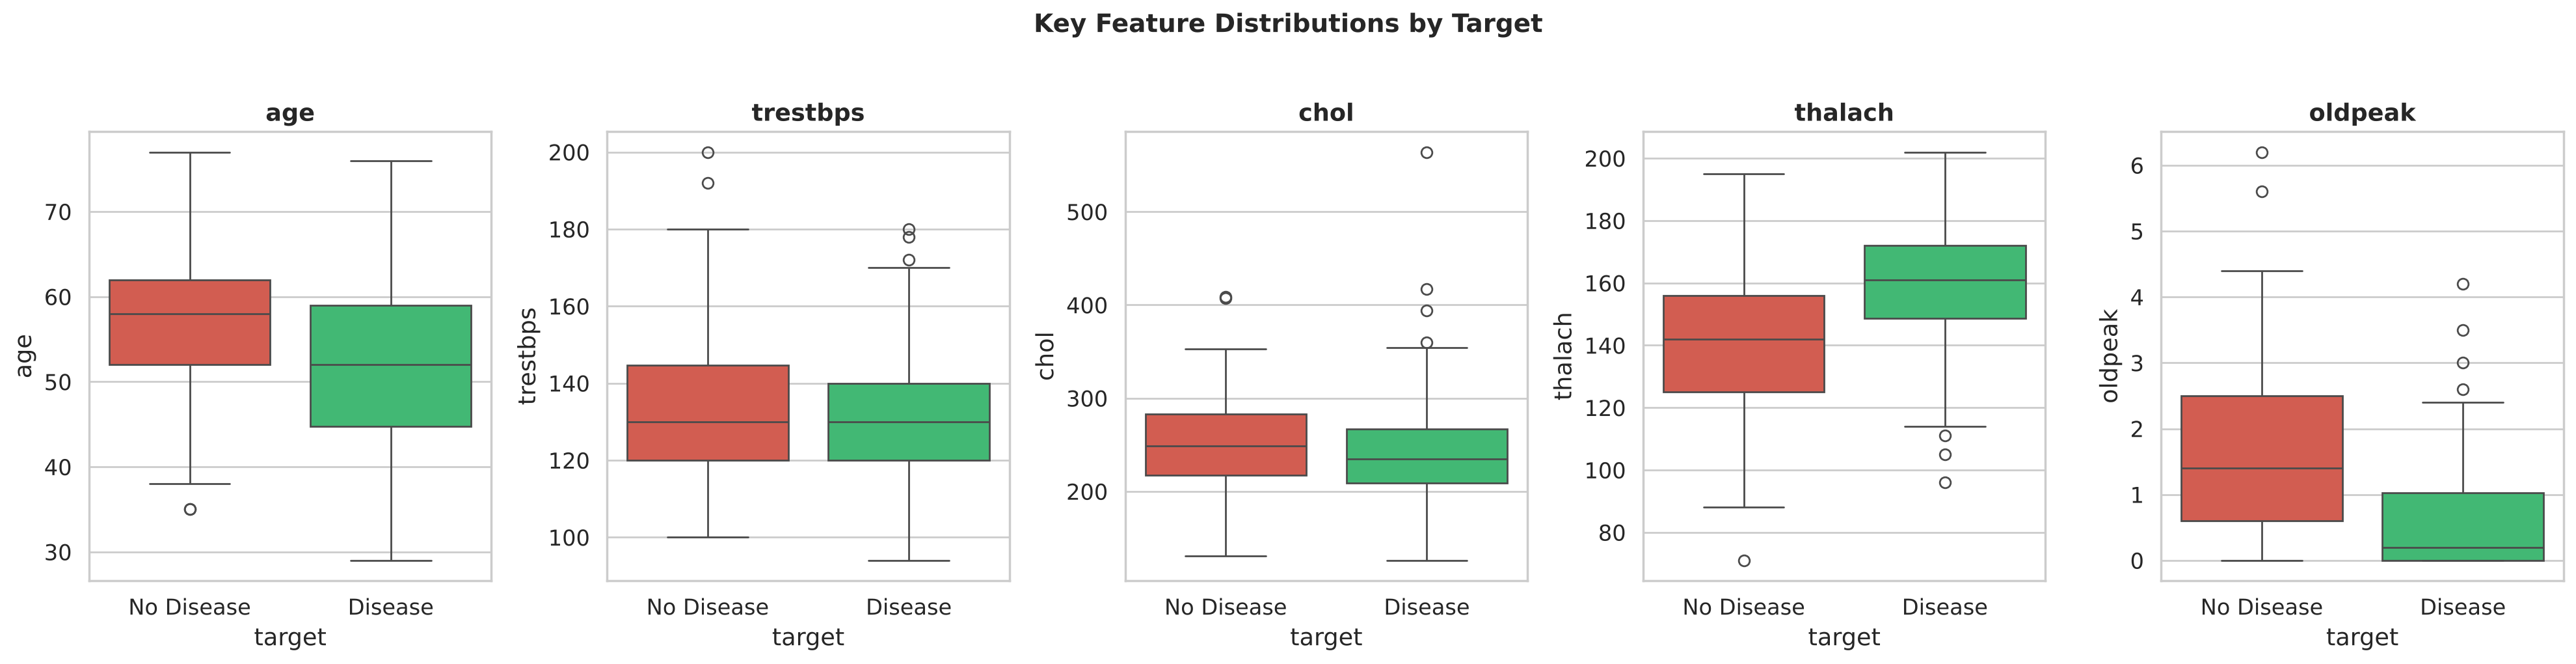

In [9]:
# --- Box Plots of Key Features ---
key_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(1, len(key_features), figsize=(20, 5))
for i, feat in enumerate(key_features):
    sns.boxplot(data=df, x='target', y=feat, palette=colors, ax=axes[i])
    axes[i].set_title(feat, fontweight='bold')
    axes[i].set_xticklabels(['No Disease', 'Disease'])
plt.suptitle('Key Feature Distributions by Target', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [10]:
# --- Correlation of each feature with the target ---
target_corr = df.corr()['target'].drop('target').sort_values()
print('Correlation with target (1 = disease):')
print(target_corr.round(2).to_string())

Correlation with target (1 = disease):
exang      -0.44
oldpeak    -0.43
ca         -0.41
thal       -0.34
sex        -0.28
age        -0.22
trestbps   -0.15
chol       -0.08
fbs        -0.03
restecg     0.13
slope       0.34
thalach     0.42
cp          0.43


---
## 3. Data Preprocessing

* **Stratified 80/20 split** keeps the 54/46 class ratio in both sets.
* **Scaling** is essential for KNN because it classifies by *distance*: without it, `chol` (hundreds) would dominate `oldpeak` (0–6). The scaler lives inside each model's `Pipeline`, so it is fitted on training data only.

In [11]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'Training set : {X_train.shape[0]} samples  {y_train.value_counts().to_dict()}')
print(f'Test set     : {X_test.shape[0]} samples  {y_test.value_counts().to_dict()}')
print(f'\nNote: each test patient is worth {100 / len(y_test):.1f} accuracy points.')

Training set : 241 samples  {1: 131, 0: 110}
Test set     : 61 samples  {1: 33, 0: 28}

Note: each test patient is worth 1.6 accuracy points.


---
## 4. Baseline KNN Model (K=5)

Baseline test accuracy : 0.8033 (80.33%)
Baseline CV accuracy   : 0.8047

Classification Report:
              precision    recall  f1-score   support

  No Disease       0.86      0.68      0.76        28
     Disease       0.77      0.91      0.83        33

    accuracy                           0.80        61
   macro avg       0.82      0.79      0.80        61
weighted avg       0.81      0.80      0.80        61



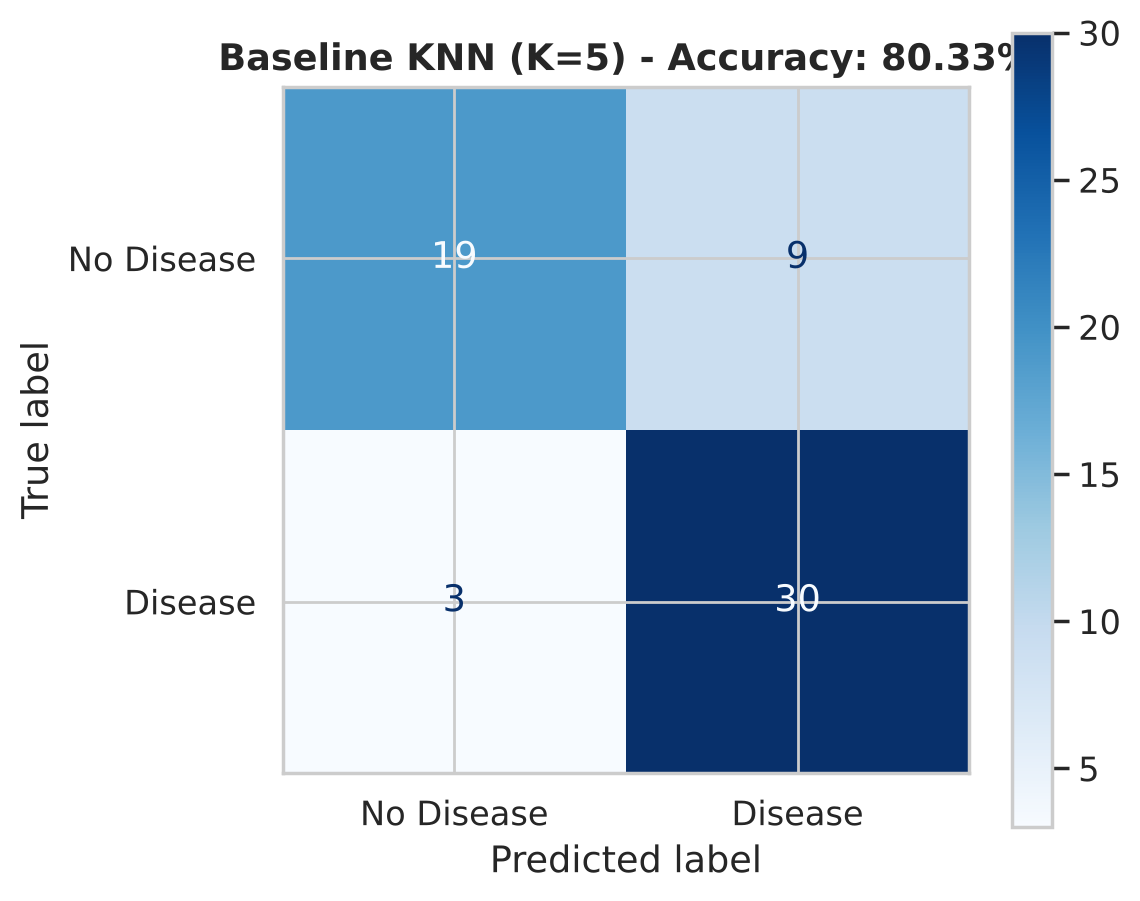

In [12]:
baseline = make_knn(n_neighbors=5).fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)
baseline_acc = accuracy_score(y_test, y_pred_baseline)
baseline_cv = cross_val_score(make_knn(n_neighbors=5), X_train, y_train, cv=CV).mean()

print(f'Baseline test accuracy : {baseline_acc:.4f} ({baseline_acc*100:.2f}%)')
print(f'Baseline CV accuracy   : {baseline_cv:.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred_baseline, target_names=['No Disease', 'Disease']))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_baseline),
                       display_labels=['No Disease', 'Disease']).plot(cmap='Blues', ax=ax, values_format='d')
ax.set_title(f'Baseline KNN (K=5) - Accuracy: {baseline_acc:.2%}', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 5. Hyperparameter Tuning - Finding Optimal K

We sweep K from 1 to 200. Small K values show **overfitting**; the range is extended well past 30 because, on this dataset, **underfitting only appears at very large K** (when each vote averages over most of the training set). K is chosen by **10-fold cross-validation on the training set**, never by the test set.

In [13]:
k_range = list(range(1, 31)) + list(range(35, 205, 5))
train_scores, test_scores, cv_scores_mean, cv_scores_std = [], [], [], []

for k in k_range:
    model = make_knn(n_neighbors=k).fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))
    cv = cross_val_score(make_knn(n_neighbors=k), X_train, y_train, cv=CV)
    cv_scores_mean.append(cv.mean())
    cv_scores_std.append(cv.std())

results_k = pd.DataFrame({'K': k_range, 'train': train_scores, 'test': test_scores,
                          'cv_mean': cv_scores_mean, 'cv_std': cv_scores_std}).set_index('K')

best_k_cv = int(results_k['cv_mean'].idxmax())
best_cv_acc = results_k.loc[best_k_cv, 'cv_mean']
print(f'Best K (10-fold CV): K = {best_k_cv}, CV accuracy = {best_cv_acc:.4f} '
      f'(± {results_k.loc[best_k_cv, "cv_std"]:.4f})')
print(f'Test accuracy at K = {best_k_cv}: {results_k.loc[best_k_cv, "test"]:.4f}')

best_se = results_k.loc[best_k_cv, 'cv_std'] / np.sqrt(CV.get_n_splits())
near_best = results_k[results_k['cv_mean'] >= best_cv_acc - best_se].index.tolist()
print(f'\nK values within one standard error of the best CV score: {near_best}')
print('-> the CV curve is flat near the top, so the exact best K is not very stable.')

Best K (10-fold CV): K = 27, CV accuracy = 0.8337 (± 0.0794)
Test accuracy at K = 27: 0.8197

K values within one standard error of the best CV score: [4, 7, 9, 11, 12, 13, 14, 15, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 35, 40, 45, 50, 55, 60, 65, 80, 90, 100, 105]
-> the CV curve is flat near the top, so the exact best K is not very stable.


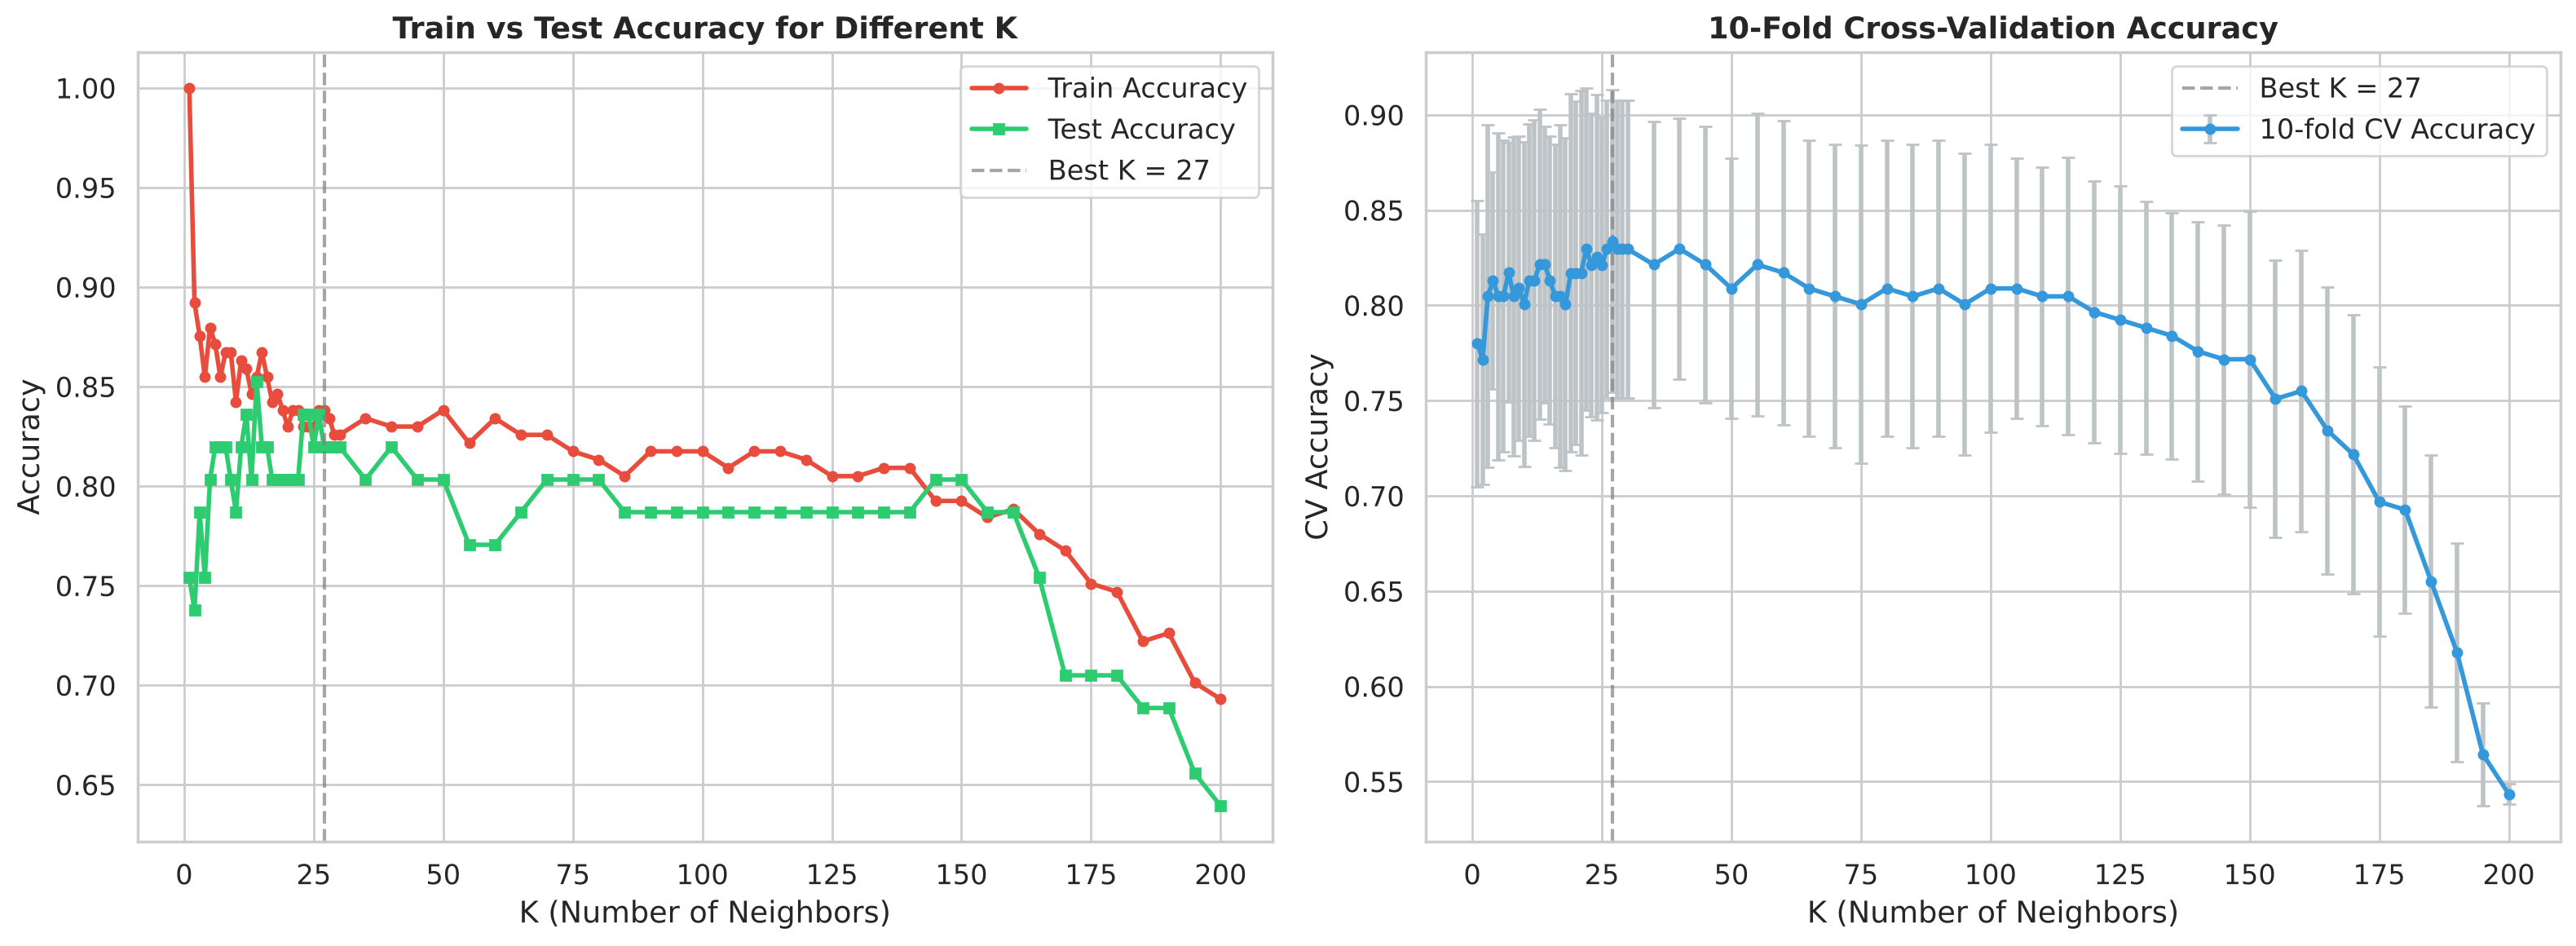

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(k_range, train_scores, 'o-', label='Train Accuracy', color='#e74c3c', linewidth=2, markersize=4)
axes[0].plot(k_range, test_scores, 's-', label='Test Accuracy', color='#2ecc71', linewidth=2, markersize=4)
axes[0].axvline(x=best_k_cv, color='gray', linestyle='--', alpha=0.7, label=f'Best K = {best_k_cv}')
axes[0].set_xlabel('K (Number of Neighbors)')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Train vs Test Accuracy for Different K', fontweight='bold')
axes[0].legend()

axes[1].errorbar(k_range, cv_scores_mean, yerr=cv_scores_std, fmt='o-', color='#3498db',
                 ecolor='#bdc3c7', capsize=3, linewidth=2, markersize=4, label='10-fold CV Accuracy')
axes[1].axvline(x=best_k_cv, color='gray', linestyle='--', alpha=0.7, label=f'Best K = {best_k_cv}')
axes[1].set_xlabel('K (Number of Neighbors)')
axes[1].set_ylabel('CV Accuracy')
axes[1].set_title('10-Fold Cross-Validation Accuracy', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 6. Overfitting vs Underfitting Analysis

| Condition | Description | Symptom |
|:--|:--|:--|
| **Overfitting** (high variance) | Model memorises training data, including noise | High train accuracy, much lower validation accuracy (large gap) |
| **Underfitting** (high bias) | Model too simple to capture the pattern | Train **and** validation accuracy both low |
| **Good fit** | Generalises to unseen data | Both high and close together |

The three K values below are **chosen from the data**, not hard-coded: K = 1 (most flexible), the CV-optimal K, and the smallest K where both training and CV accuracy have clearly dropped.

In [15]:
ref_train = results_k.loc[best_k_cv, 'train']
underfit_candidates = results_k[(results_k.index > best_k_cv)
                                & (results_k['train'] < ref_train - 0.05)
                                & (results_k['cv_mean'] < best_cv_acc - 0.05)]
underfit_k = int(underfit_candidates.index.min()) if len(underfit_candidates) else int(results_k.index.max())


def diagnose(train_acc, cv_acc):
    gap = train_acc - cv_acc
    if gap > 0.10:
        return 'OVERFITTING (large train-validation gap)'
    if train_acc < ref_train - 0.05 and cv_acc < best_cv_acc - 0.05:
        return 'UNDERFITTING (train and validation both drop)'
    return 'GOOD FIT (high and close)'


demo_ks = {'K=1': 1, f'K={best_k_cv} (CV optimal)': best_k_cv, f'K={underfit_k}': underfit_k}

print('Overfitting vs Underfitting Demonstration')
print('-' * 96)
print(f"{'':24s}{'Train':>8s}{'CV':>8s}{'Test':>8s}{'Gap':>8s}   Diagnosis")
for label, k in demo_ks.items():
    r = results_k.loc[k]
    print(f"{label:24s}{r['train']:8.4f}{r['cv_mean']:8.4f}{r['test']:8.4f}{r['train'] - r['cv_mean']:8.4f}   "
          f"{diagnose(r['train'], r['cv_mean'])}")

flat = results_k.loc[5:150]
print(f"\nBetween K=5 and K=150, CV accuracy stays in {flat['cv_mean'].min():.3f}–{flat['cv_mean'].max():.3f}: "
      'this dataset tolerates very smooth decision boundaries, so underfitting appears only at very large K.')

Overfitting vs Underfitting Demonstration
------------------------------------------------------------------------------------------------
                           Train      CV    Test     Gap   Diagnosis
K=1                       1.0000  0.7798  0.7541  0.2202   OVERFITTING (large train-validation gap)
K=27 (CV optimal)         0.8382  0.8337  0.8197  0.0045   GOOD FIT (high and close)
K=155                     0.7842  0.7508  0.7869  0.0334   UNDERFITTING (train and validation both drop)

Between K=5 and K=150, CV accuracy stays in 0.772–0.834: this dataset tolerates very smooth decision boundaries, so underfitting appears only at very large K.


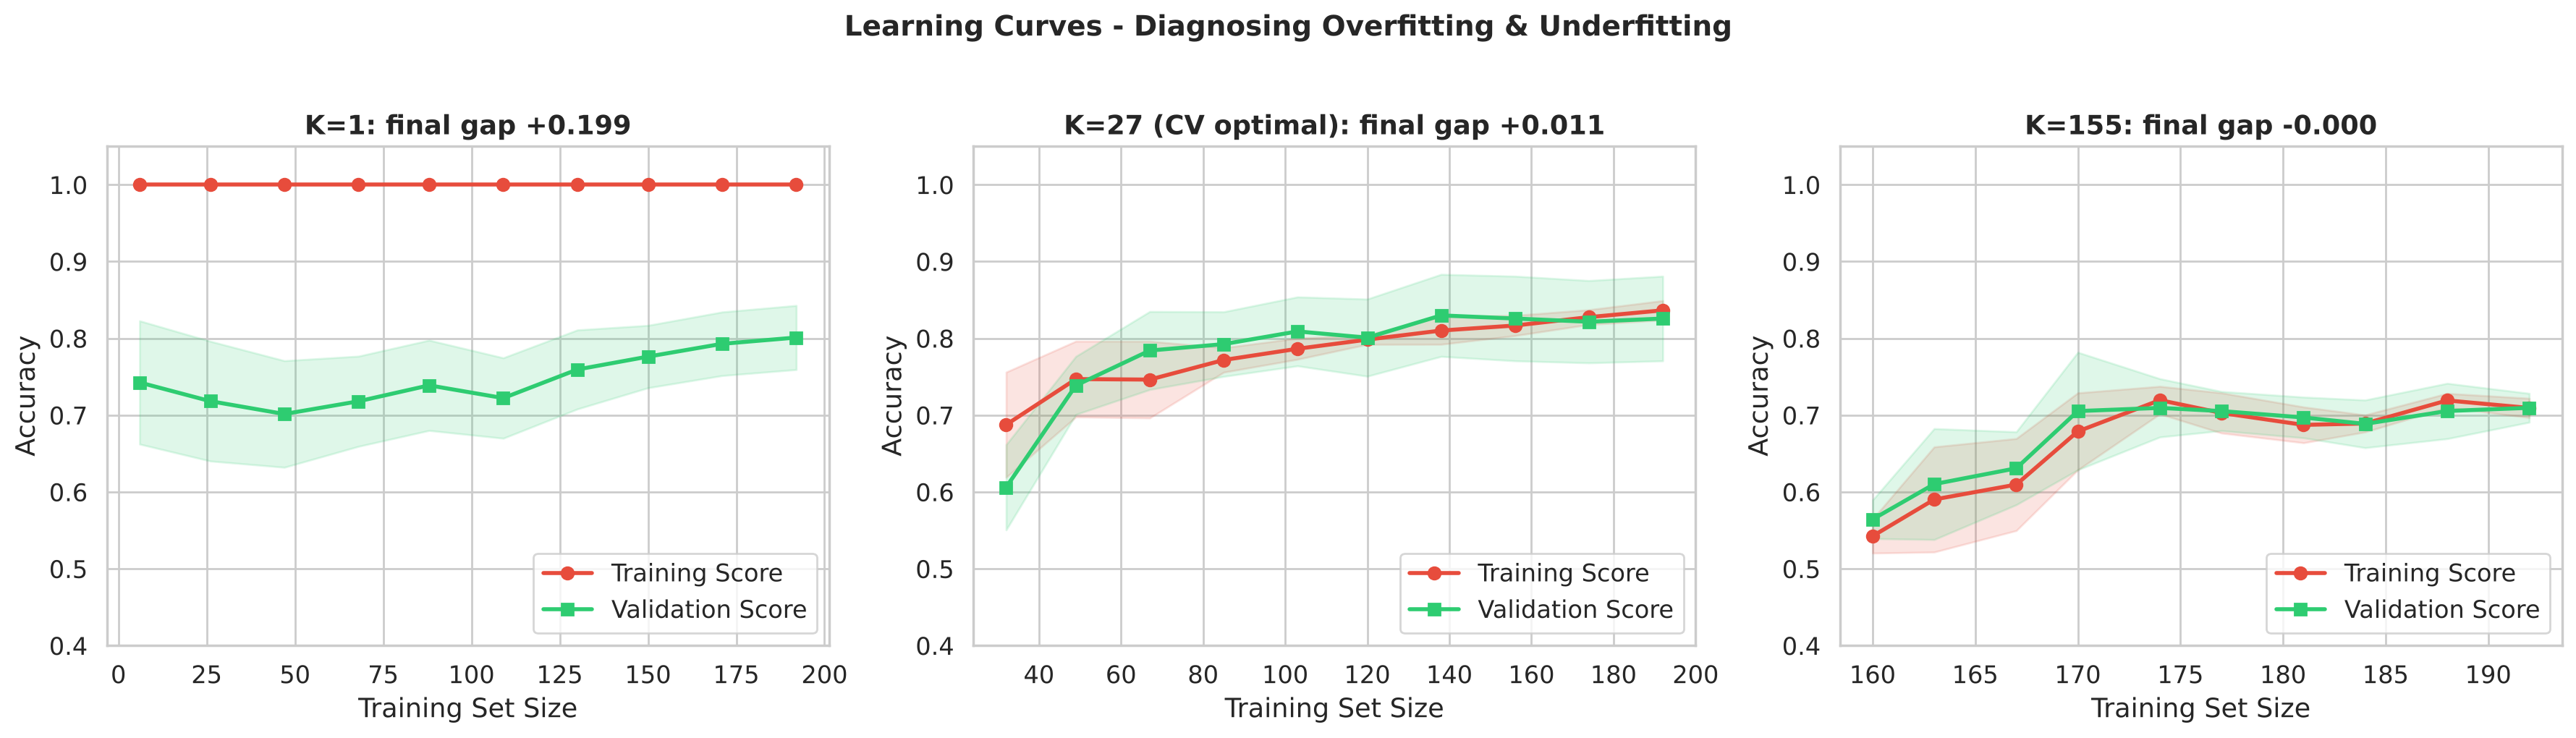

Interpretation (computed from the curves above):
  K=1                      -> OVERFITTING (large train-validation gap)
  K=27 (CV optimal)        -> GOOD FIT (high and close)
  K=155                    -> UNDERFITTING (train and validation both drop)


In [16]:
# --- Learning Curves (diagnose overfitting / underfitting) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
max_train = int(len(X_train) * 0.8)  # largest training fold with 5-fold CV

for idx, (label, k) in enumerate(demo_ks.items()):
    # KNN needs more training samples than K, so the smallest size is K + 5
    sizes = np.unique(np.linspace(min(k + 5, max_train), max_train, 10).astype(int))
    train_sizes, train_lc, val_lc = learning_curve(
        make_knn(n_neighbors=k), X_train, y_train,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
        scoring='accuracy', train_sizes=sizes,
    )
    tm, ts = train_lc.mean(axis=1), train_lc.std(axis=1)
    vm, vs = val_lc.mean(axis=1), val_lc.std(axis=1)
    axes[idx].fill_between(train_sizes, tm - ts, tm + ts, alpha=0.15, color='#e74c3c')
    axes[idx].fill_between(train_sizes, vm - vs, vm + vs, alpha=0.15, color='#2ecc71')
    axes[idx].plot(train_sizes, tm, 'o-', color='#e74c3c', label='Training Score', linewidth=2)
    axes[idx].plot(train_sizes, vm, 's-', color='#2ecc71', label='Validation Score', linewidth=2)
    axes[idx].set_xlabel('Training Set Size')
    axes[idx].set_ylabel('Accuracy')
    axes[idx].set_title(f'{label}: final gap {tm[-1] - vm[-1]:+.3f}', fontweight='bold')
    axes[idx].legend(loc='lower right')
    axes[idx].set_ylim(0.4, 1.05)

plt.suptitle('Learning Curves - Diagnosing Overfitting & Underfitting', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('Interpretation (computed from the curves above):')
for label, k in demo_ks.items():
    r = results_k.loc[k]
    print(f"  {label:24s} -> {diagnose(r['train'], r['cv_mean'])}")

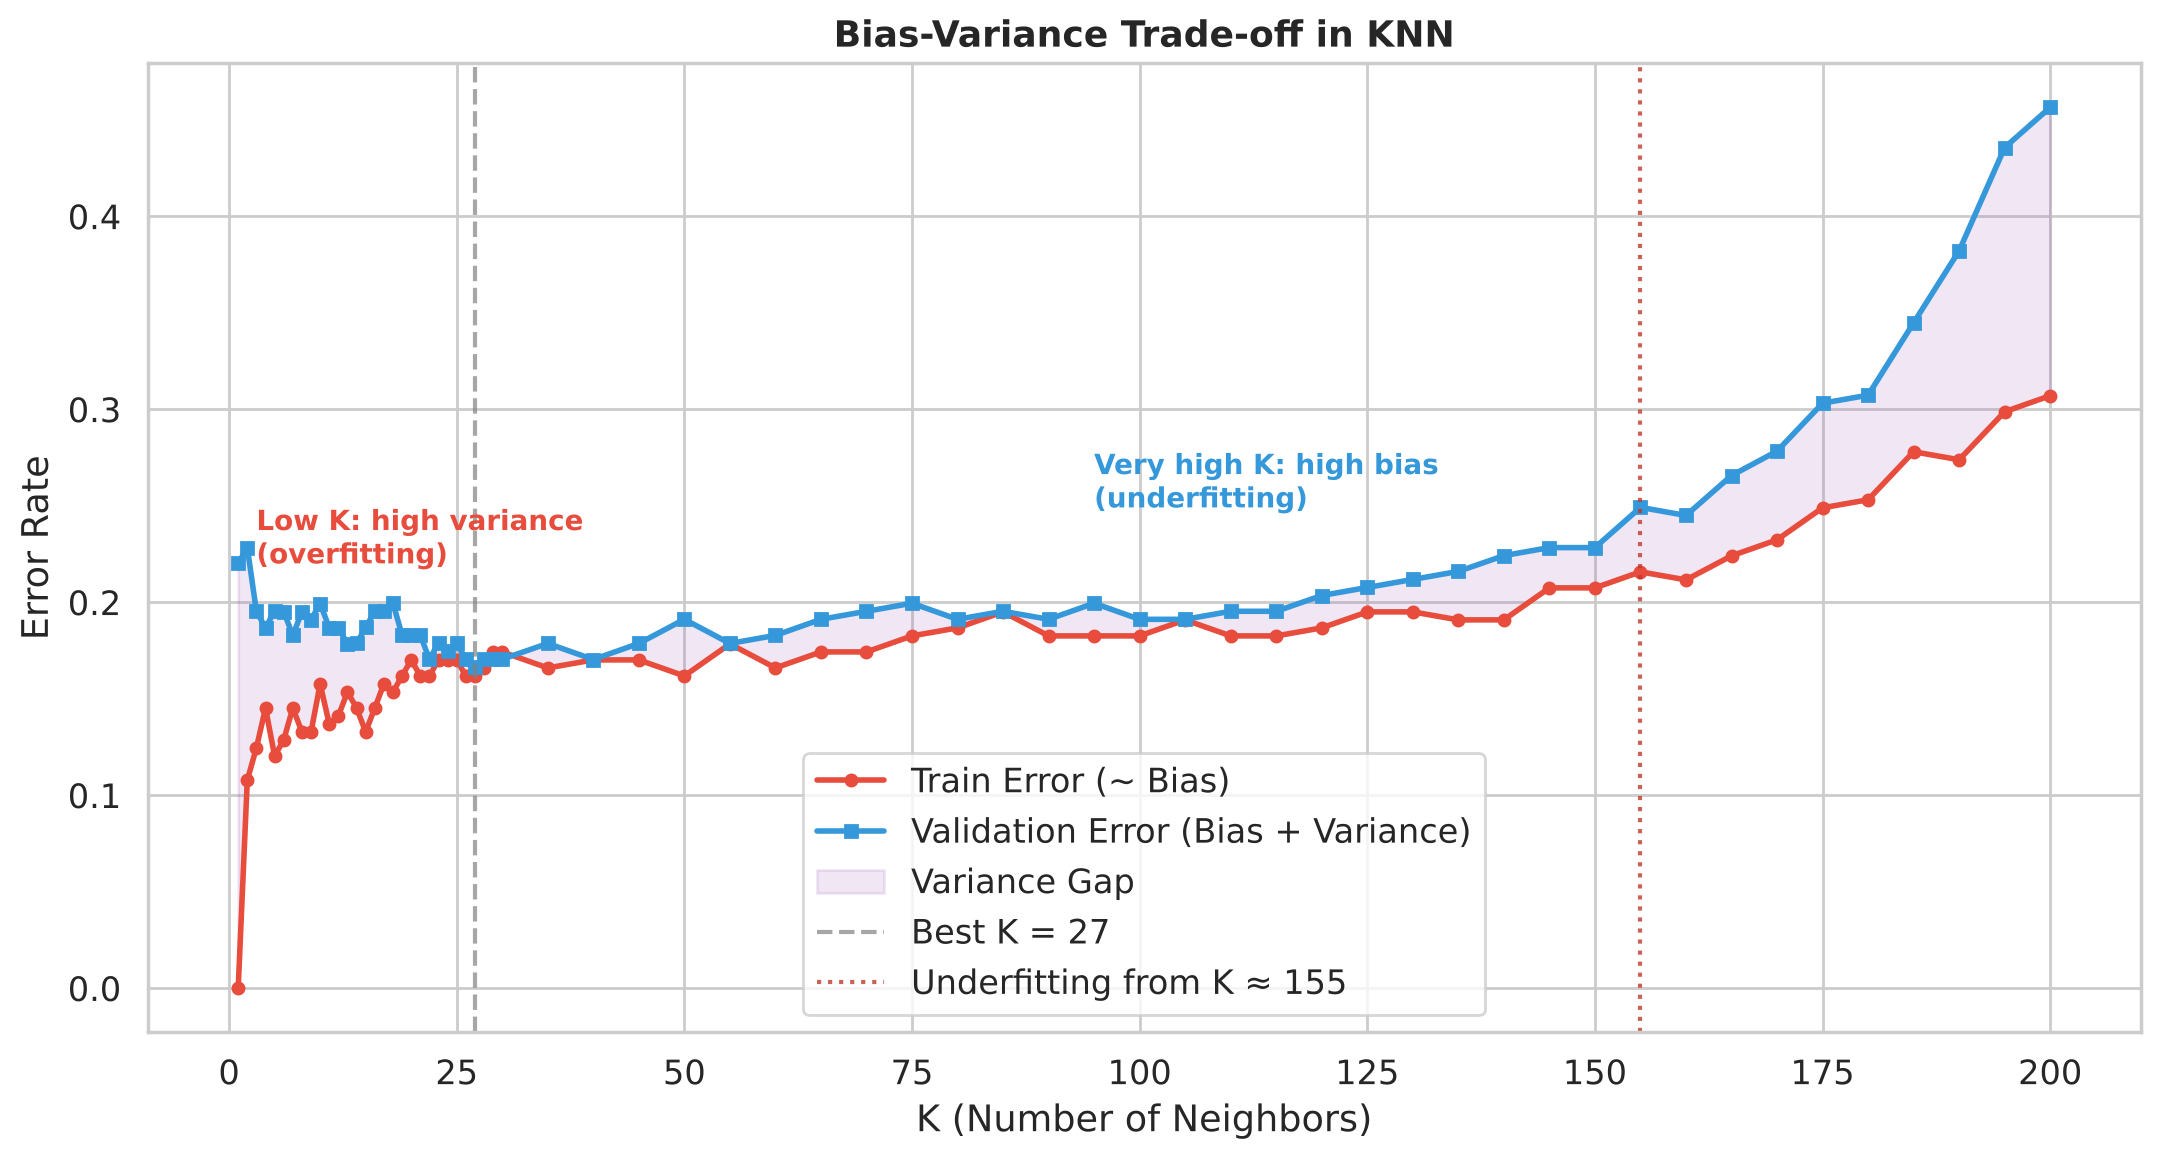

In [17]:
# --- Bias-Variance Trade-off Visualization ---
fig, ax = plt.subplots(figsize=(11, 6))
error_train = 1 - results_k['train']
error_cv = 1 - results_k['cv_mean']
ax.plot(k_range, error_train, 'o-', label='Train Error (~ Bias)', color='#e74c3c', linewidth=2, markersize=4)
ax.plot(k_range, error_cv, 's-', label='Validation Error (Bias + Variance)', color='#3498db', linewidth=2, markersize=4)
ax.fill_between(k_range, error_train, error_cv, alpha=0.15, color='#9b59b6', label='Variance Gap')
ax.axvline(x=best_k_cv, color='gray', linestyle='--', alpha=0.7, label=f'Best K = {best_k_cv}')
ax.axvline(x=underfit_k, color='#c0392b', linestyle=':', alpha=0.8, label=f'Underfitting from K ≈ {underfit_k}')
ax.set_xlabel('K (Number of Neighbors)')
ax.set_ylabel('Error Rate')
ax.set_title('Bias-Variance Trade-off in KNN', fontweight='bold', fontsize=13)
ax.legend()
ax.annotate('Low K: high variance\n(overfitting)', xy=(3, error_cv.loc[1]), fontsize=10, color='#e74c3c', fontweight='bold')
ax.annotate('Very high K: high bias\n(underfitting)', xy=(underfit_k - 60, error_cv.loc[underfit_k]),
            fontsize=10, color='#3498db', fontweight='bold')
plt.tight_layout()
plt.show()

---
## 7. Data Augmentation (SMOTE - Synthetic Minority Oversampling)

SMOTE creates synthetic samples of the minority class. It is placed **inside** the pipeline, so it only ever touches training data (in each CV fold too). Because our classes are already close to balanced (54/46), we expect little benefit; this section tests that.

In [18]:
smote_model = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=RANDOM_STATE)),
    ('knn', KNeighborsClassifier(n_neighbors=best_k_cv)),
])

counts_before = y_train.value_counts().to_dict()
_, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(StandardScaler().fit_transform(X_train), y_train)
print(f'Training classes before SMOTE: {counts_before}')
print(f'Training classes after  SMOTE: {pd.Series(y_res).value_counts().to_dict()}')

smote_model.fit(X_train, y_train)
y_pred_smote = smote_model.predict(X_test)
smote_acc = accuracy_score(y_test, y_pred_smote)
smote_cv = cross_val_score(smote_model, X_train, y_train, cv=CV).mean()

y_pred_plain = make_knn(n_neighbors=best_k_cv).fit(X_train, y_train).predict(X_test)
plain_acc = accuracy_score(y_test, y_pred_plain)

print(f'\nK = {best_k_cv}   without SMOTE: test {plain_acc:.4f} | CV {best_cv_acc:.4f}')
print(f'K = {best_k_cv}   with SMOTE   : test {smote_acc:.4f} | CV {smote_cv:.4f}')
print(f'Predictions changed for {int((y_pred_smote != y_pred_plain).sum())} of {len(y_test)} test patients.')
print('\nClassification Report (SMOTE):')
print(classification_report(y_test, y_pred_smote, target_names=['No Disease', 'Disease']))

Training classes before SMOTE: {1: 131, 0: 110}
Training classes after  SMOTE: {1: 131, 0: 131}

K = 27   without SMOTE: test 0.8197 | CV 0.8337
K = 27   with SMOTE   : test 0.8197 | CV 0.8172
Predictions changed for 2 of 61 test patients.

Classification Report (SMOTE):
              precision    recall  f1-score   support

  No Disease       0.90      0.68      0.78        28
     Disease       0.78      0.94      0.85        33

    accuracy                           0.82        61
   macro avg       0.84      0.81      0.81        61
weighted avg       0.83      0.82      0.82        61



---
## 8. Advanced Hyperparameter Tuning (GridSearchCV)

Tuning several hyperparameters together:
- **n_neighbors** (K): 1–25
- **weights**: `uniform` (each neighbour votes equally) or `distance` (closer neighbours count more)
- **metric**: Euclidean, Manhattan, or Minkowski with p = 3

`p` only matters for the Minkowski metric (Minkowski with p = 1 or 2 *is* Manhattan or Euclidean), so the grid is written to avoid duplicate combinations.

In [19]:
param_grid = [
    {'knn__n_neighbors': list(range(1, 26)),
     'knn__weights': ['uniform', 'distance'],
     'knn__metric': ['euclidean', 'manhattan']},
    {'knn__n_neighbors': list(range(1, 26)),
     'knn__weights': ['uniform', 'distance'],
     'knn__metric': ['minkowski'],
     'knn__p': [3]},
]

grid_search = GridSearchCV(make_knn(), param_grid, cv=CV, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

best_params = {k.replace('knn__', ''): v for k, v in grid_search.best_params_.items()}
best_grid_cv = grid_search.best_score_
best_knn = grid_search.best_estimator_
y_pred_best = best_knn.predict(X_test)
best_test_acc = accuracy_score(y_test, y_pred_best)
best_train_acc = best_knn.score(X_train, y_train)

print(f'\nUnique combinations tested: {len(grid_search.cv_results_["params"])}')
print(f'Best Parameters : {best_params}')
print(f'Best CV Accuracy: {best_grid_cv:.4f}')
print(f'Train Accuracy  : {best_train_acc:.4f}')
print(f'Test Accuracy   : {best_test_acc:.4f}')
if best_params.get('weights') == 'distance':
    print('\nNote: distance weighting gives each training point full weight on itself, so train accuracy '
          'is ~100% by construction. Judge this model by CV and test accuracy, not train accuracy.')
print('\nClassification Report (Best Model):')
print(classification_report(y_test, y_pred_best, target_names=['No Disease', 'Disease']))

Fitting 10 folds for each of 150 candidates, totalling 1500 fits



Unique combinations tested: 150
Best Parameters : {'metric': 'manhattan', 'n_neighbors': 19, 'weights': 'distance'}
Best CV Accuracy: 0.8462
Train Accuracy  : 1.0000
Test Accuracy   : 0.7541

Note: distance weighting gives each training point full weight on itself, so train accuracy is ~100% by construction. Judge this model by CV and test accuracy, not train accuracy.

Classification Report (Best Model):
              precision    recall  f1-score   support

  No Disease       0.84      0.57      0.68        28
     Disease       0.71      0.91      0.80        33

    accuracy                           0.75        61
   macro avg       0.78      0.74      0.74        61
weighted avg       0.77      0.75      0.75        61



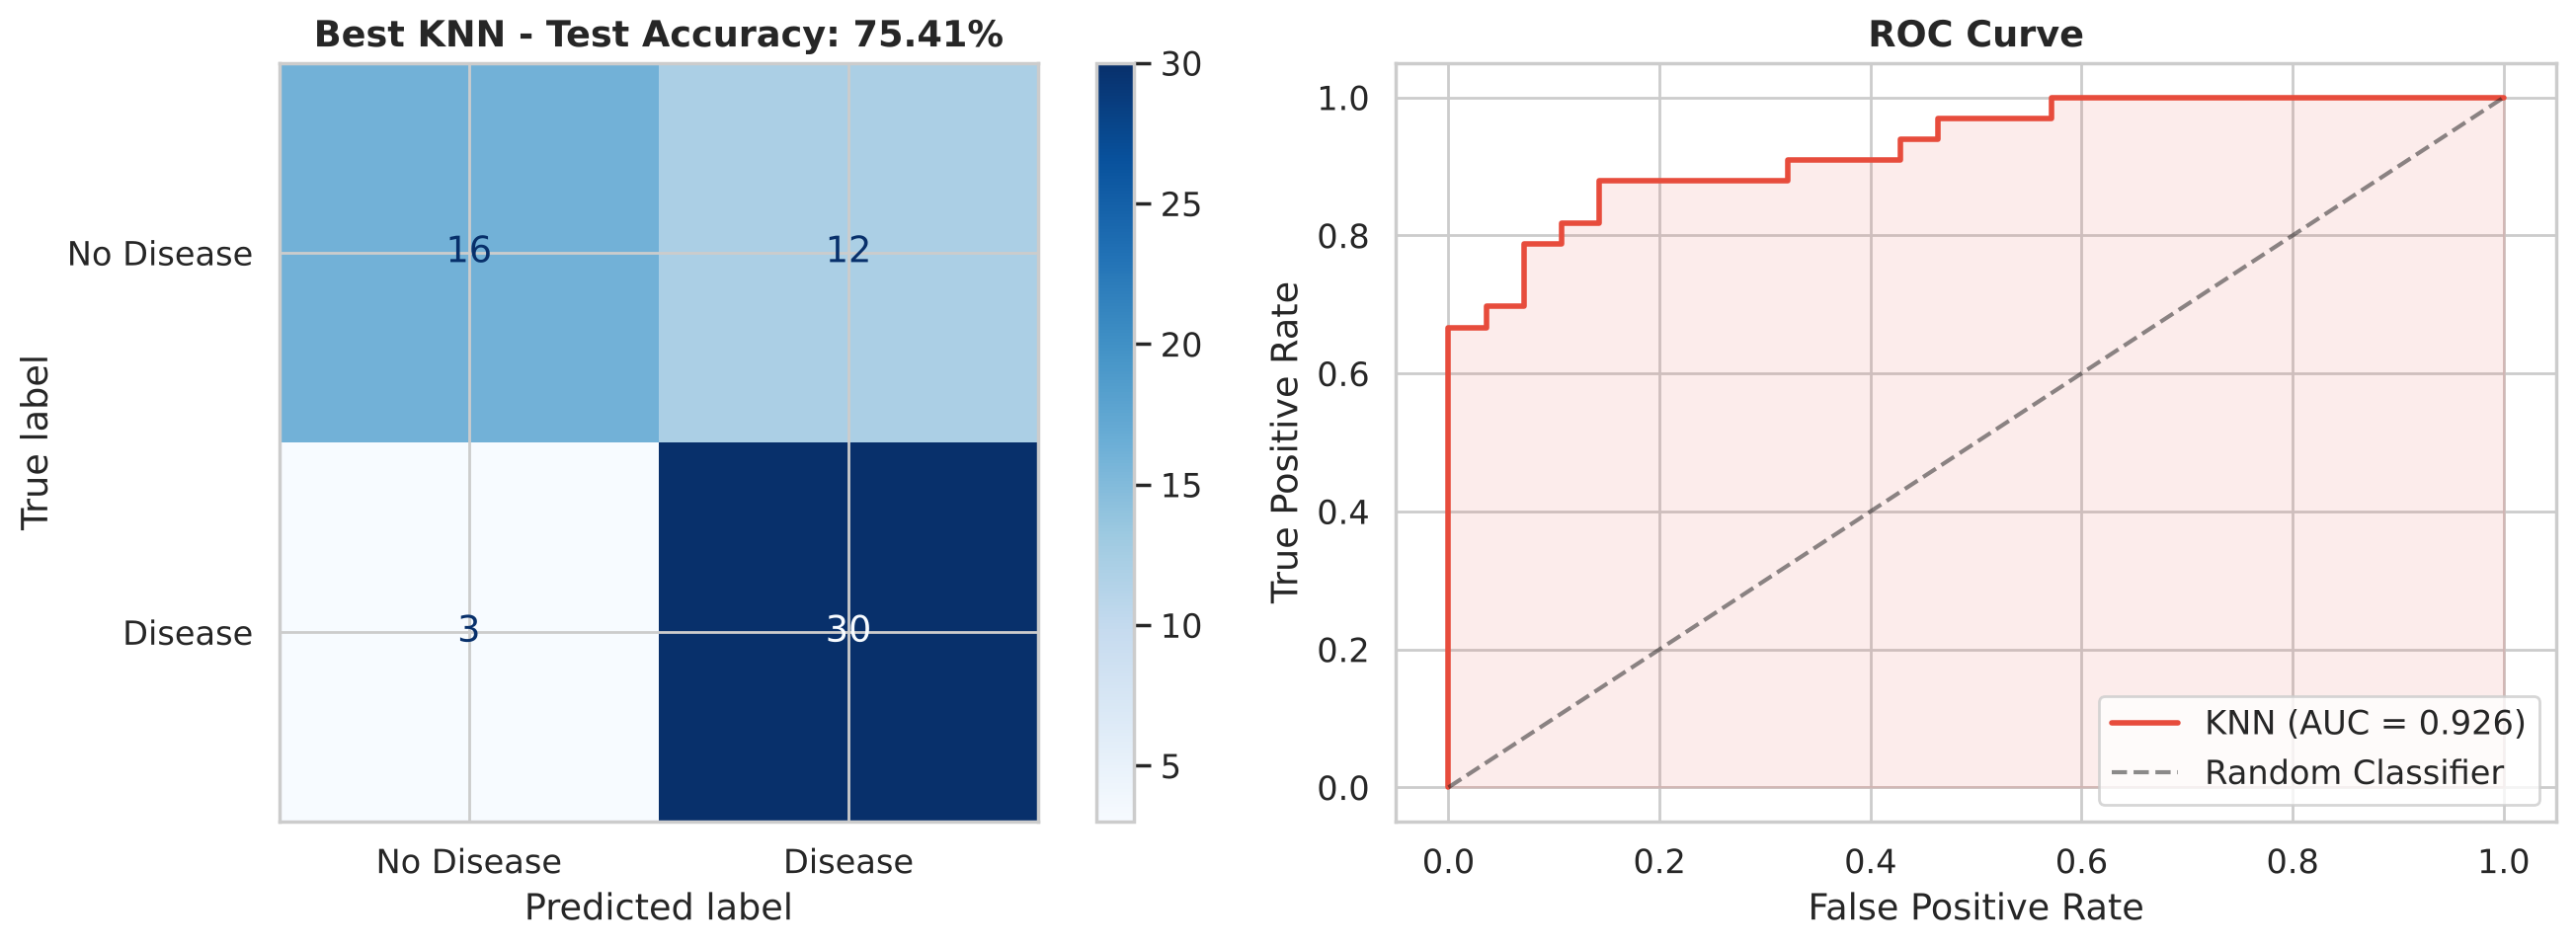

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_best),
                       display_labels=['No Disease', 'Disease']).plot(cmap='Blues', ax=axes[0], values_format='d')
axes[0].set_title(f'Best KNN - Test Accuracy: {best_test_acc:.2%}', fontweight='bold')

y_prob = best_knn.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
axes[1].plot(fpr, tpr, color='#e74c3c', linewidth=2, label=f'KNN (AUC = {auc_score:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Classifier')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#e74c3c')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

---
## 9. Scaler Comparison

In [21]:
print('SCALER COMPARISON (best grid-search parameters)')
print('-' * 55)
scaler_results = {}
for name, sc in {'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler()}.items():
    m = make_knn(scaler=sc, **best_params)
    cv_acc = cross_val_score(m, X_train, y_train, cv=CV).mean()
    test_acc = m.fit(X_train, y_train).score(X_test, y_test)
    scaler_results[name] = (cv_acc, test_acc)
    print(f'  {name:16s} => CV: {cv_acc:.4f} | Test: {test_acc:.4f}')

SCALER COMPARISON (best grid-search parameters)
-------------------------------------------------------
  StandardScaler   => CV: 0.8462 | Test: 0.7541
  MinMaxScaler     => CV: 0.8337 | Test: 0.7705


---
## 10. Robust Comparison with Repeated Cross-Validation

The test set has only 61 patients, so one or two patients change test accuracy by 1.6–3.3 points. To compare models fairly we use **repeated stratified 10-fold CV on the whole dataset (10 repeats = 100 train/test splits)** and report mean ± standard deviation for accuracy, **recall on the disease class** (missed sick patients matter most in screening) and AUC.

In [22]:
models = {
    'K=1 (overfit)': make_knn(n_neighbors=1),
    'Baseline K=5': make_knn(n_neighbors=5),
    f'CV-tuned K={best_k_cv}': make_knn(n_neighbors=best_k_cv),
    f'SMOTE + K={best_k_cv}': ImbPipeline([('scaler', StandardScaler()),
                                          ('smote', SMOTE(random_state=RANDOM_STATE)),
                                          ('knn', KNeighborsClassifier(n_neighbors=best_k_cv))]),
    'GridSearch best': make_knn(**best_params),
    f'K={underfit_k} (underfit)': make_knn(n_neighbors=underfit_k),
}

rcv = RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    acc = cross_val_score(m, X, y, cv=rcv, scoring='accuracy')
    rec = cross_val_score(m, X, y, cv=rcv, scoring='recall')
    auc = cross_val_score(m, X, y, cv=rcv, scoring='roc_auc')
    # spread across the 10 repeats (each repeat = one full 10-fold pass over all patients)
    rep = lambda s: s.reshape(10, 10).mean(axis=1).std()
    rows.append({'Model': name,
                 'Accuracy': f'{acc.mean():.3f} ± {rep(acc):.3f}',
                 'Recall (disease)': f'{rec.mean():.3f} ± {rep(rec):.3f}',
                 'AUC': f'{auc.mean():.3f} ± {rep(auc):.3f}',
                 '_acc': acc.mean(), '_rep': rep(acc)})

robust = pd.DataFrame(rows)
print('Mean over 100 folds ± standard deviation across the 10 repeats')
print(robust.drop(columns=['_acc', '_rep']).to_string(index=False))

top = robust.loc[robust['_acc'].idxmax()]
tied = robust[robust['_acc'] >= top['_acc'] - 2 * top['_rep']]['Model'].tolist()
print(f"\nModels within two repeat-standard-deviations of the best ({top['Model']}): {tied}")

Mean over 100 folds ± standard deviation across the 10 repeats
           Model      Accuracy Recall (disease)           AUC
   K=1 (overfit) 0.762 ± 0.010    0.806 ± 0.013 0.757 ± 0.010
    Baseline K=5 0.822 ± 0.005    0.865 ± 0.008 0.884 ± 0.004
   CV-tuned K=27 0.826 ± 0.005    0.932 ± 0.003 0.906 ± 0.006
    SMOTE + K=27 0.833 ± 0.004    0.900 ± 0.010 0.906 ± 0.006
 GridSearch best 0.825 ± 0.007    0.901 ± 0.008 0.914 ± 0.006
K=155 (underfit) 0.790 ± 0.003    0.963 ± 0.003 0.899 ± 0.004

Models within two repeat-standard-deviations of the best (SMOTE + K=27): ['CV-tuned K=27', 'SMOTE + K=27', 'GridSearch best']


---
## 11. Final Summary

In [23]:
def test_metrics(model):
    p = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    return accuracy_score(y_test, p), recall_score(y_test, p), roc_auc_score(y_test, prob), int(((p == 0) & (y_test == 1)).sum())

fitted = {name: m.fit(X_train, y_train) for name, m in models.items()}
summary = pd.DataFrame(
    [(name, *test_metrics(m)) for name, m in fitted.items()],
    columns=['Model', 'Test accuracy', 'Disease recall', 'Test AUC', 'Sick patients missed'],
).set_index('Model').round(4)

print('=' * 70)
print('FINAL SUMMARY (61-patient test set)')
print('=' * 70)
print(summary.to_string())

print(f'''
Best grid-search parameters: {best_params}  (CV accuracy {best_grid_cv:.4f})

Overfitting vs underfitting:
  * K=1            -> {diagnose(results_k.loc[1, 'train'], results_k.loc[1, 'cv_mean'])}
  * K={best_k_cv:<13d} -> {diagnose(results_k.loc[best_k_cv, 'train'], results_k.loc[best_k_cv, 'cv_mean'])}
  * K={underfit_k:<13d} -> {diagnose(results_k.loc[underfit_k, 'train'], results_k.loc[underfit_k, 'cv_mean'])}

Did tuning increase accuracy?
  * CV accuracy : baseline {baseline_cv:.4f} -> CV-tuned K {best_cv_acc:.4f} -> grid search {best_grid_cv:.4f}
  * Test accuracy: baseline {baseline_acc:.4f} -> CV-tuned K {results_k.loc[best_k_cv, 'test']:.4f} -> grid search {best_test_acc:.4f}
  * See Section 10: under repeated CV, models in {tied} are statistically tied.

Techniques applied:
  [+] Feature scaling inside a Pipeline (StandardScaler vs MinMaxScaler)
  [+] Hyperparameter tuning: K, weights, distance metric (optimizer/activation tuning does not apply to KNN)
  [+] Stratified 10-fold cross-validation and repeated cross-validation
  [+] Data augmentation with SMOTE (inside the pipeline)
  [+] Overfitting/underfitting analysis: K sweep to 200, learning curves, bias-variance plot
''')

FINAL SUMMARY (61-patient test set)
                  Test accuracy  Disease recall  Test AUC  Sick patients missed
Model                                                                          
K=1 (overfit)            0.7541          0.8182    0.7484                     6
Baseline K=5             0.8033          0.9091    0.8674                     3
CV-tuned K=27            0.8197          0.9697    0.9242                     1
SMOTE + K=27             0.8197          0.9394    0.9140                     2
GridSearch best          0.7541          0.9091    0.9264                     3
K=155 (underfit)         0.7869          1.0000    0.8463                     0

Best grid-search parameters: {'metric': 'manhattan', 'n_neighbors': 19, 'weights': 'distance'}  (CV accuracy 0.8462)

Overfitting vs underfitting:
  * K=1            -> OVERFITTING (large train-validation gap)
  * K=27            -> GOOD FIT (high and close)
  * K=155           -> UNDERFITTING (train and validation both d

## 12. Conclusions

**1. KNN works well for this real-life screening problem.** The CV-tuned model (K = 27) reaches **81.97% test accuracy**, **0.97 recall on the disease class** (it missed 1 of 33 sick patients) and **0.924 AUC**. Under repeated cross-validation it averages about 82.6% accuracy and 0.93 recall.

**2. Overfitting and underfitting are both clearly visible.**

| K | Train | CV | Test | Diagnosis |
|:-:|:-:|:-:|:-:|:--|
| 1 | 100.00% | 77.98% | 75.41% | **Overfitting**: a 22-point train-validation gap; the model memorises noise |
| 27 | 83.82% | 83.37% | 81.97% | **Good fit**: high accuracy, train and validation almost equal |
| 155 | 78.42% | 75.08% | 78.69% | **Underfitting**: train and validation accuracy both drop; by K = 200 validation error reaches about 45% |

Between K ≈ 5 and K ≈ 150 accuracy barely changes, so this dataset tolerates very smooth decision boundaries. That is why underfitting only shows up at very large K.

**3. Fine-tuning improved CV accuracy; its effect on test accuracy is within noise.**
- CV accuracy rose from 80.47% (baseline K = 5) to 83.37% (CV-tuned K) to 84.62% (grid search).
- Test accuracy rose from 80.33% to 81.97% with the tuned K: one extra patient correct.
- The grid-search winner (Manhattan, K = 19, distance weights) scored highest on CV but only 75.41% on the test set. Distance weighting gives 100% training accuracy by construction, and on 61 test patients the 6.5-point drop is just 4 patients.
- Repeated cross-validation (Section 10) shows the CV-tuned K, SMOTE + K and grid-search models are statistically tied, while K = 1 and K = 155 are clearly worse.

**4. SMOTE did not help.** It changed 2 of 61 test predictions and left test accuracy unchanged. The classes were already close to balanced (54/46), so there was little imbalance to correct.

**5. Optimizers and activation functions do not apply to KNN**, which has no training loop. The equivalent tuning knobs were explored instead: K, distance metric, vote weighting and feature scaling. StandardScaler slightly beat MinMaxScaler on CV accuracy.

**Limitations and next steps:** the dataset is small (302 patients), so single-split results are noisy. A screening tool should be tuned for recall rather than accuracy, and the model should be benchmarked against logistic regression, random forest or SVM.